# Room 1 reflectivity production

Generate `reflectivity.h5` using `examples/example_room_1/room_1_reflectivity.json`, then load and display it using the existing codebase functions. The map represents assigned material reflectivity at the first ray hit, averaged over valid samples; it is not inferred from photon counts.

## Environment

Use the project's Python environment as the notebook kernel. For native generation, launch Jupyter from a shell with the runtime activated (Jupyter must already be available):

```bash
source ./activate.sh --full
jupyter lab examples/example_room_1/reflectivity.ipynb
```

Existing HDF5 results can be plotted without the native runtime.


In [1]:
from pathlib import Path
import json
import subprocess
import sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "examples/example_room_1/room_1_reflectivity.json").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from within the repository.")
sys.path.insert(0, str(root / "src"))
from spad_noise_injection.diffuse_map import (
    read_diffuse_from_h5,
    display_diffuse_map,
)

config_path = root / "examples/example_room_1/room_1_reflectivity.json"
output_dir = root / "examples/example_room_1"
h5_path = output_dir / "reflectivity.h5"


## 1. Inspect the production configuration

The scene is `examples/example_room_1/room_1.usda`. The configuration preserves the saved camera pose, Z-up direction, receiver dimensions, baseline and 110° horizontal/vertical field of view. It uses a 60 × 60 grid, 25,000 samples per launch and seed 4.


In [2]:
config = json.loads(config_path.read_text())
print(json.dumps(config, indent=2))


{
  "output_dir": ".",
  "stages": [
    {
      "command": "diffuse-map",
      "options": {
        "scene": "room_1.usda",
        "output": "{output_dir}/reflectivity.h5",
        "camera_position": [
          300.3439483285741,
          95.83950936290105,
          281.81155637239846
        ],
        "look_at": [
          0.34394832857406676,
          95.83950936290105,
          280.0
        ],
        "up": [
          0.0,
          0.0,
          1.0
        ],
        "baseline_offset": [
          5,
          0,
          0
        ],
        "detector_width": 18,
        "detector_height": 18,
        "fov_x": 110,
        "fov_y": 110,
        "width": 60,
        "height": 60,
        "samples_per_ray": 25000,
        "seed": 4
      }
    }
  ]
}


## 2. Produce the HDF5 map

The equivalent terminal command is:

```bash
synthetic-data run --config examples/example_room_1/room_1_reflectivity.json
```

Reuse the existing output by default. Set `regenerate = True` to rerun the native simulation and overwrite it. Generation requires the built native tracer and the activated oneAPI runtime. The output dataset is `diffuse_data`, with `diffuse_avg` and `valid_count` fields.


In [3]:
regenerate = False
if regenerate or not h5_path.exists():
    subprocess.run(
        [sys.executable, "-m", "synthetic_data_generation", "run",
         "--config", str(config_path)],
        cwd=root, check=True,
    )
print(f"Using {h5_path}")


Using /home/peizhao/synthetic_data_generation/examples/example_room_1/reflectivity.h5


## 3. Read and plot using the shared functions

`read_diffuse_from_h5()` reads `diffuse_avg`; `display_diffuse_map()` displays the transposed map with a lower origin and a viridis colour map. The shared plot uses automatic colour limits and the label “Diffuse intensity”; it does not mask `valid_count` or save a PNG. This replaces the standalone room-specific plotting script. Any existing `reflectivity.png` and `reflectivity_validation.json` are previous artifacts and are not refreshed by this notebook.


Map shape: (60, 60)


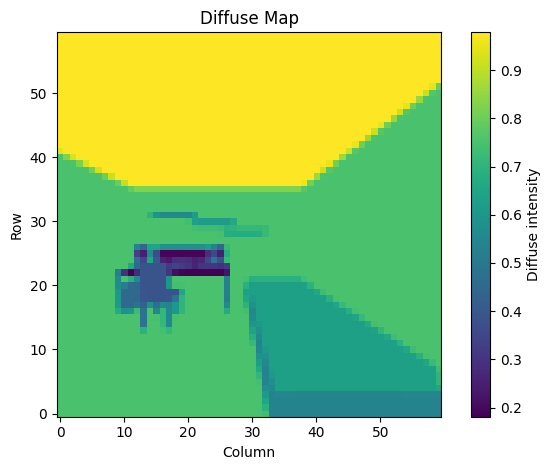

In [4]:
reflectivity = read_diffuse_from_h5(str(h5_path))
print(f"Map shape: {reflectivity.shape}")
display_diffuse_map(reflectivity)
